In [15]:
import os
import re
import string
import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt

from collections import Counter, defaultdict
from spellchecker import SpellChecker
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

In [16]:
%pip install pandas nltk matplotlib pyspellchecker scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
with open("alice.txt", "r", encoding="utf-8") as file:
    text = file.read()

print("Dataset loaded successfully")
print("Total characters:", len(text))
print("\nSample text:")
print(text[:500])

Dataset loaded successfully
Total characters: 163950

Sample text:
The Project Gutenberg eBook of Alice's Adventures in Wonderland
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using 


In [18]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

text = text.lower()
tokens = word_tokenize(text)

words = [
    word for word in tokens
    if word.isalpha()
]

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("Total tokens:", len(tokens))
print("Words after punctuation removal:", len(words))
print("Words after stopword removal:", len(filtered_words))
print("\nSample processed words:")
print(filtered_words[:30])

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Total tokens: 38626
Words after punctuation removal: 29822
Words after stopword removal: 13568

Sample processed words:
['project', 'gutenberg', 'ebook', 'alice', 'adventures', 'wonderland', 'ebook', 'use', 'anyone', 'anywhere', 'united', 'states', 'parts', 'world', 'cost', 'almost', 'restrictions', 'whatsoever', 'may', 'copy', 'give', 'away', 'terms', 'project', 'gutenberg', 'license', 'included', 'ebook', 'online', 'located']


## Top 20 Most Frequent Words

This bar chart displays the 20 most frequent words in the preprocessed text corpus. It helps identify common vocabulary and understand word-frequency distribution.

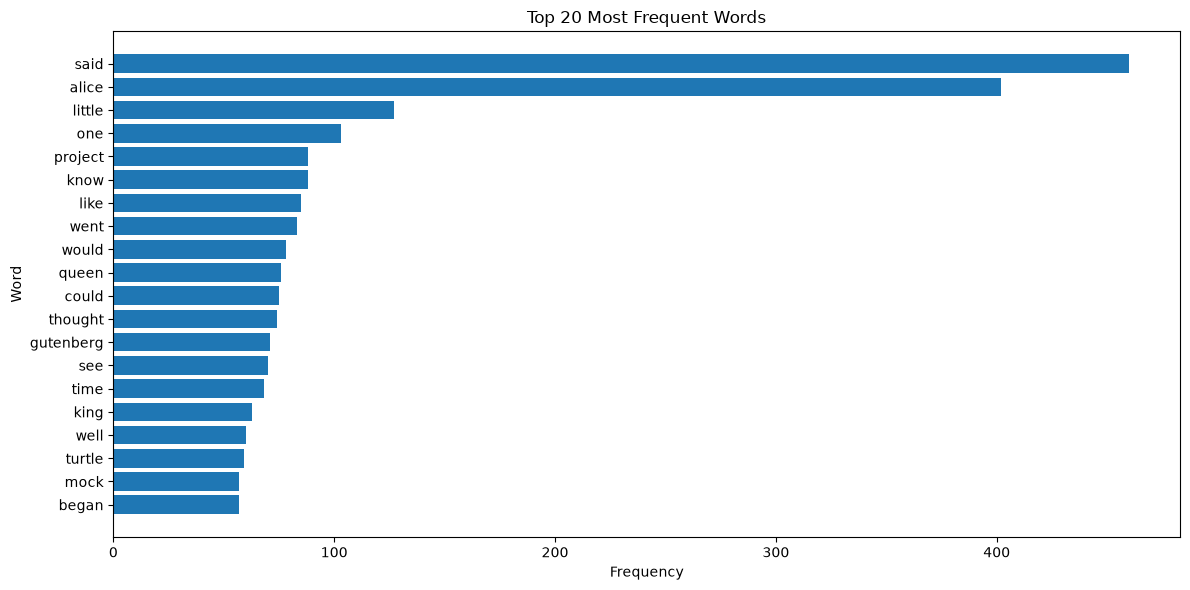

,Word,Frequency
0,said,460
1,alice,402
2,little,127
3,one,103
4,project,88
5,know,88
6,like,85
7,went,83
8,would,78
9,queen,76


In [19]:
word_counts = Counter(filtered_words)

top_20_words = word_counts.most_common(20)

freq_df = pd.DataFrame(
    top_20_words,
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(12, 6))
plt.barh(freq_df["Word"][::-1], freq_df["Frequency"][::-1])
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

display(freq_df)

In [20]:
autocomplete_tokens = [
    word for word in word_tokenize(text.lower())
    if word.isalpha()
]

bigram_model = defaultdict(Counter)
trigram_model = defaultdict(Counter)

for i in range(len(autocomplete_tokens) - 1):
    current_word = autocomplete_tokens[i]
    next_word = autocomplete_tokens[i + 1]
    bigram_model[current_word][next_word] += 1

for i in range(len(autocomplete_tokens) - 2):
    first_word = autocomplete_tokens[i]
    second_word = autocomplete_tokens[i + 1]
    next_word = autocomplete_tokens[i + 2]
    trigram_model[(first_word, second_word)][next_word] += 1

print("Bigram model created:", len(bigram_model))
print("Trigram model created:", len(trigram_model))

Bigram model created: 2922
Trigram model created: 15919


In [21]:
def predict_next_words(prefix, top_n=3):
    words = [
        word for word in word_tokenize(prefix.lower())
        if word.isalpha()
    ]

    if len(words) >= 2:
        context = tuple(words[-2:])
        predictions = trigram_model.get(context, Counter())

        if predictions:
            return predictions.most_common(top_n)

    if len(words) >= 1:
        context = words[-1]
        predictions = bigram_model.get(context, Counter())
        return predictions.most_common(top_n)

    return []

In [22]:
test_prefixes = [
    "alice",
    "white rabbit",
    "the king",
    "the queen",
    "said alice",
    "in the",
    "i am",
    "it was",
    "the rabbit",
    "mock turtle"
]

results = []

for prefix in test_prefixes:
    predictions = predict_next_words(prefix, top_n=3)

    results.append({
        "Input Prefix": prefix,
        "Top 3 Predictions": ", ".join(
            [word for word, count in predictions]
        ),
        "Prediction Counts": ", ".join(
            [str(count) for word, count in predictions]
        )
    })

autocomplete_df = pd.DataFrame(results)
display(autocomplete_df)

,Input Prefix,Top 3 Predictions,Prediction Counts
0,alice,"and, was, i","20, 17, 15"
1,white rabbit,"with, who, blew","2, 2, 2"
2,the king,"and, said, the","10, 8, 5"
3,the queen,"s, and, said","8, 7, 5"
4,said alice,"i, and, in","9, 7, 7"
5,in the,"united, distance, air","10, 7, 5"
6,i am,"so, very, older","1, 1, 1"
7,it was,"the, all, a","7, 4, 4"
8,the rabbit,"s, sends, say","4, 2, 2"
9,mock turtle,"said, s, and","4, 3, 3"


In [23]:
spell = SpellChecker()

spell.word_frequency.load_words(set(autocomplete_tokens))

print("Autocorrect model created successfully")

Autocorrect model created successfully


In [24]:
misspelled_words = [
    "alce", "adventurs", "wondrland", "rabitt", "quene",
    "chesire", "catte", "hattter", "turtel", "gryphon",
    "beginnning", "frend", "thier", "becaus", "peple",
    "writting", "recieve", "beleive", "throught", "wonderfull"
]

expected_words = [
    "alice", "adventures", "wonderland", "rabbit", "queen",
    "cheshire", "caterpillar", "hatter", "turtle", "gryphon",
    "beginning", "friend", "their", "because", "people",
    "writing", "receive", "believe", "through", "wonderful"
]

corrected_words = [
    spell.correction(word) for word in misspelled_words
]

autocorrect_df = pd.DataFrame({
    "Misspelled Word": misspelled_words,
    "Expected Word": expected_words,
    "Predicted Correction": corrected_words
})

autocorrect_df["Correct"] = (
    autocorrect_df["Expected Word"]
    == autocorrect_df["Predicted Correction"]
)

display(autocorrect_df)

accuracy = autocorrect_df["Correct"].mean() * 100

print("Correct predictions:", int(autocorrect_df["Correct"].sum()), "out of", len(autocorrect_df))
print("Autocorrect accuracy:", round(accuracy, 2), "%")

,Misspelled Word,Expected Word,Predicted Correction,Correct
0,alce,alice,ace,False
1,adventurs,adventures,adventure,False
2,wondrland,wonderland,wonderland,True
3,rabitt,rabbit,habit,False
4,quene,queen,queen,True
5,chesire,cheshire,cheshire,True
6,catte,caterpillar,cattle,False
7,hattter,hatter,hatter,True
8,turtel,turtle,turtle,True
9,gryphon,gryphon,gryphon,True


Correct predictions: 15 out of 20
Autocorrect accuracy: 75.0 %


In [25]:
def levenshtein_distance(word1, word2):
    rows = len(word1) + 1
    cols = len(word2) + 1

    dp = [[0] * cols for _ in range(rows)]

    for i in range(rows):
        dp[i][0] = i

    for j in range(cols):
        dp[0][j] = j

    for i in range(1, rows):
        for j in range(1, cols):
            cost = 0 if word1[i - 1] == word2[j - 1] else 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + cost
            )

    return dp[-1][-1]

print("Levenshtein distance function created")

Levenshtein distance function created


In [26]:
vocabulary = set(autocomplete_tokens)

def levenshtein_autocorrect(word):
    word = word.lower()

    if word in vocabulary:
        return word

    candidates = [
        candidate for candidate in vocabulary
        if abs(len(candidate) - len(word)) <= 2
    ]

    if not candidates:
        return word

    best_candidate = min(
        candidates,
        key=lambda candidate: levenshtein_distance(word, candidate)
    )

    return best_candidate

print("Levenshtein autocorrect model created")

Levenshtein autocorrect model created


In [27]:
autocorrect_df["Levenshtein Correction"] = [
    levenshtein_autocorrect(word)
    for word in misspelled_words
]

autocorrect_df["PySpellChecker Correct"] = (
    autocorrect_df["Predicted Correction"]
    == autocorrect_df["Expected Word"]
)

autocorrect_df["Levenshtein Correct"] = (
    autocorrect_df["Levenshtein Correction"]
    == autocorrect_df["Expected Word"]
)

display(autocorrect_df)

comparison_df = pd.DataFrame({
    "Algorithm": ["PySpellChecker", "Levenshtein Distance"],
    "Correct Predictions": [
        int(autocorrect_df["PySpellChecker Correct"].sum()),
        int(autocorrect_df["Levenshtein Correct"].sum())
    ],
    "Accuracy (%)": [
        autocorrect_df["PySpellChecker Correct"].mean() * 100,
        autocorrect_df["Levenshtein Correct"].mean() * 100
    ]
})

display(comparison_df.round(2))

,Misspelled Word,Expected Word,Predicted Correction,Correct,Levenshtein Correction,PySpellChecker Correct,Levenshtein Correct
0,alce,alice,ace,False,alice,False,True
1,adventurs,adventures,adventure,False,adventures,False,True
2,wondrland,wonderland,wonderland,True,wonderland,True,True
3,rabitt,rabbit,habit,False,rabbits,False,False
4,quene,queen,queen,True,queer,True,False
5,chesire,cheshire,cheshire,True,cheshire,True,True
6,catte,caterpillar,cattle,False,cattle,False,False
7,hattter,hatter,hatter,True,hatter,True,True
8,turtel,turtle,turtle,True,turtle,True,True
9,gryphon,gryphon,gryphon,True,gryphon,True,True


,Algorithm,Correct Predictions,Accuracy (%)
0,PySpellChecker,15,75.0
1,Levenshtein Distance,14,70.0


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = autocorrect_df["Expected Word"]

py_predictions = autocorrect_df["Predicted Correction"]
lev_predictions = autocorrect_df["Levenshtein Correction"]

py_precision = precision_score(
    y_true, py_predictions, average="micro", zero_division=0
)
py_recall = recall_score(
    y_true, py_predictions, average="micro", zero_division=0
)
py_f1 = f1_score(
    y_true, py_predictions, average="micro", zero_division=0
)

lev_precision = precision_score(
    y_true, lev_predictions, average="micro", zero_division=0
)
lev_recall = recall_score(
    y_true, lev_predictions, average="micro", zero_division=0
)
lev_f1 = f1_score(
    y_true, lev_predictions, average="micro", zero_division=0
)

metrics_df = pd.DataFrame({
    "Algorithm": ["PySpellChecker", "Levenshtein Distance"],
    "Precision": [py_precision, lev_precision],
    "Recall": [py_recall, lev_recall],
    "F1-score": [py_f1, lev_f1],
    "Accuracy (%)": [
        py_predictions.eq(y_true).mean() * 100,
        lev_predictions.eq(y_true).mean() * 100
    ]
})

display(metrics_df.round(3))

,Algorithm,Precision,Recall,F1-score,Accuracy (%)
0,PySpellChecker,0.75,0.75,0.75,75.0
1,Levenshtein Distance,0.70,0.70,0.70,70.0


## Autocorrect Confusion Matrix

The confusion matrix compares the expected words with the predicted corrections for both autocorrect methods. It helps identify correct predictions and incorrect corrections.

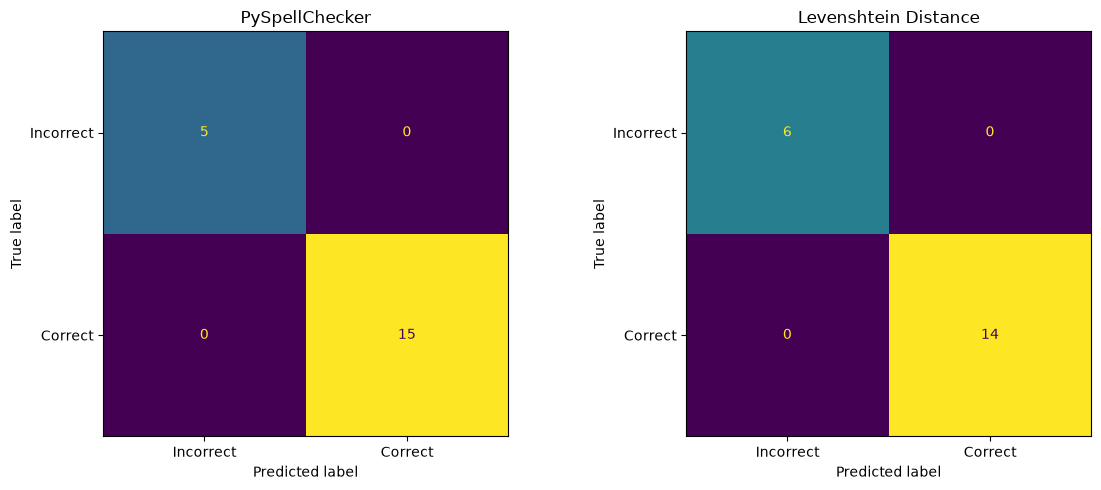

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, title in [
    (axes[0], py_predictions, "PySpellChecker"),
    (axes[1], lev_predictions, "Levenshtein Distance")
]:
    labels = ["Incorrect", "Correct"]

    actual_status = y_true.eq(predictions).map({
        True: "Correct",
        False: "Incorrect"
    })

    predicted_status = y_true.eq(predictions).map({
        True: "Correct",
        False: "Incorrect"
    })

    cm = confusion_matrix(
        actual_status,
        predicted_status,
        labels=labels
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    display_cm.plot(ax=ax, colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [30]:
autocomplete_test_data = [
    ("alice", "was"),
    ("white rabbit", "hole"),
    ("the king", "said"),
    ("the queen", "said"),
    ("said alice", "and"),
    ("in the", "garden"),
    ("i am", "sure"),
    ("it was", "a"),
    ("the rabbit", "said"),
    ("mock turtle", "said")
]

evaluation_rows = []

for prefix, expected_next in autocomplete_test_data:
    predictions = predict_next_words(prefix, top_n=3)
    predicted_words = [word for word, count in predictions]

    evaluation_rows.append({
        "Prefix": prefix,
        "Expected Next Word": expected_next,
        "Top 3 Predictions": ", ".join(predicted_words),
        "Hit": expected_next in predicted_words
    })

autocomplete_eval_df = pd.DataFrame(evaluation_rows)
display(autocomplete_eval_df)

hits = int(autocomplete_eval_df["Hit"].sum())
total = len(autocomplete_eval_df)

precision_at_3 = hits / (total * 3)
recall_at_3 = hits / total

print("Precision@3:", round(precision_at_3, 3))
print("Recall@3:", round(recall_at_3, 3))
print("Hit rate:", round(recall_at_3 * 100, 2), "%")

,Prefix,Expected Next Word,Top 3 Predictions,Hit
0,alice,was,"and, was, i",True
1,white rabbit,hole,"with, who, blew",False
2,the king,said,"and, said, the",True
3,the queen,said,"s, and, said",True
4,said alice,and,"i, and, in",True
5,in the,garden,"united, distance, air",False
6,i am,sure,"so, very, older",False
7,it was,a,"the, all, a",True
8,the rabbit,said,"s, sends, say",False
9,mock turtle,said,"said, s, and",True


Precision@3: 0.2
Recall@3: 0.6
Hit rate: 60.0 %


In [31]:
final_comparison = pd.DataFrame({
    "Model": [
        "Autocomplete - Bigram/Trigram",
        "Autocorrect - PySpellChecker",
        "Autocorrect - Levenshtein"
    ],
    "Evaluation": [
        "Precision@3 / Recall@3",
        "Exact-word accuracy",
        "Exact-word accuracy"
    ],
    "Score": [
        f"{precision_at_3:.3f} / {recall_at_3:.3f}",
        f"{py_predictions.eq(y_true).mean() * 100:.2f}%",
        f"{lev_predictions.eq(y_true).mean() * 100:.2f}%"
    ]
})

display(final_comparison)

,Model,Evaluation,Score
0,Autocomplete - Bigram/Trigram,Precision@3 / Recall@3,0.200 / 0.600
1,Autocorrect - PySpellChecker,Exact-word accuracy,75.00%
2,Autocorrect - Levenshtein,Exact-word accuracy,70.00%


In [32]:
print("AUTOCOMPLETE AND AUTOCORRECT - FINAL SUMMARY")
print("-" * 45)

print("Dataset: Alice's Adventures in Wonderland")
print("Preprocessed words:", len(filtered_words))
print("Autocomplete test prefixes:", len(test_prefixes))

print("\nPySpellChecker accuracy:",
      round(py_predictions.eq(y_true).mean() * 100, 2), "%")

print("Levenshtein accuracy:",
      round(lev_predictions.eq(y_true).mean() * 100, 2), "%")

print("Autocomplete Precision@3:",
      round(precision_at_3, 3))

print("Autocomplete Recall@3:",
      round(recall_at_3, 3))

print("\nAnalysis completed successfully.")

AUTOCOMPLETE AND AUTOCORRECT - FINAL SUMMARY
---------------------------------------------
Dataset: Alice's Adventures in Wonderland
Preprocessed words: 13568
Autocomplete test prefixes: 10

PySpellChecker accuracy: 75.0 %
Levenshtein accuracy: 70.0 %
Autocomplete Precision@3: 0.2
Autocomplete Recall@3: 0.6

Analysis completed successfully.


## Limitations

1. The dataset is based on a single book, so the vocabulary may not represent everyday conversations or other domains.
2. The bigram and trigram models rely on word frequency and do not understand meaning or context deeply.
3. PySpellChecker may suggest incorrect corrections when a word is rare or missing from its dictionary.
4. Levenshtein distance selects words based on character similarity and may not identify the intended meaning.
5. The test dataset contains only 20 misspelled words and 10 autocomplete prefixes, which is too small for a reliable real-world performance assessment.
6. The simplified autocomplete evaluation uses manually selected expected words, so the results should not be treated as a definitive benchmark.

## Recommendations

1. Use a larger and more diverse text corpus for better vocabulary coverage.
2. Test the system with a larger set of manually verified prefixes and misspelled words.
3. Use context-aware language models to improve autocomplete suggestions.
4. Combine edit distance, word frequency, and keyboard-neighbour information for autocorrect.
5. Evaluate the system using a separate test dataset and report accuracy, precision, recall, and F1-score clearly.

## Conclusion

This project demonstrates a basic NLP-based autocomplete and autocorrect system using Python. Bigram and trigram frequency models generate next-word suggestions, while PySpellChecker and Levenshtein distance provide spelling correction. The comparison highlights the strengths and limitations of frequency-based prediction and character-distance methods. More data and context-aware techniques could improve performance in practical applications.